
# Import Libraries


In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# Data Loading


In [47]:
content = pd.read_csv("Content_Addition_Fact.csv", sep=";")
bts = pd.read_csv("BTS_Fact.csv", sep=";", encoding="mac_roman")

show = pd.read_csv("show_dim.csv", sep=";", encoding="cp1252")
date = pd.read_csv("date_dim.csv", sep=";")
country = pd.read_csv("country_dim.csv", sep=";")
genres = pd.read_csv("genres_dim.csv", sep=";")
person = pd.read_csv("person_dim.csv", sep=";",encoding="mac_roman")

show_country = pd.read_csv("show_country_bridge.csv", sep=";")
show_genres = pd.read_csv("show_genres_bridge.csv", sep=";")

# Data Quality Check

In [48]:
content.head()

,tmdb_score,show_id,date_id,is_high_quality_flag,is_movie_flag
0,7.093,s1,1,0,1
1,7.900,s2,2,0,0
2,7.146,s3,2,0,0
3,5.714,s4,2,0,0
4,6.476,s5,2,0,0


In [49]:
content.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8743 entries, 0 to 8742
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tmdb_score            8743 non-null   float64
 1   show_id               8743 non-null   object 
 2   date_id               8743 non-null   int64  
 3   is_high_quality_flag  8743 non-null   int64  
 4   is_movie_flag         8743 non-null   int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 341.7+ KB


In [50]:
content.isnull().sum()

,0
tmdb_score,0
show_id,0
date_id,0
is_high_quality_flag,0
is_movie_flag,0


In [51]:
content.duplicated().sum()

np.int64(0)

# Data Integration

In [52]:
df = content.merge(show, on="show_id", how="left")
df = df.merge(date, on="date_id", how="left")

df.head()

,tmdb_score,show_id,date_id,is_high_quality_flag,is_movie_flag,type,title,runtime_minutes,date_added,content_rating,listed_in,description,month,day,year,day_of_week
0,7.093,s1,1,0,1,Movie,dick johnson is dead,90 min,2021-09-25,PG-13,Documentaries,"As her father nears the end of his life, filmm...",9,25,2021,Saturday
1,7.900,s2,2,0,0,TV Show,blood water,2 Seasons,2021-09-24,TV-MA,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",9,24,2021,Friday
2,7.146,s3,2,0,0,TV Show,ganglands,1 Season,2021-09-24,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,9,24,2021,Friday
3,5.714,s4,2,0,0,TV Show,jailbirds new orleans,1 Season,2021-09-24,TV-MA,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",9,24,2021,Friday
4,6.476,s5,2,0,0,TV Show,kota factory,2 Seasons,2021-09-24,TV-MA,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,9,24,2021,Friday


# KPI Analysis

In [53]:
high_quality_pct = df["is_high_quality_flag"].mean() * 100

print(f"High Quality Content: {high_quality_pct:.2f}%")

High Quality Content: 4.93%


In [54]:
movie_pct = df["is_movie_flag"].mean() * 100

print(f"Movie Content: {movie_pct:.2f}%")

Movie Content: 69.68%


In [55]:
avg_score = df["tmdb_score"].mean()

print(f"Average TMDB Score: {avg_score:.2f}")

Average TMDB Score: 6.25


# Data Analysis & Visualization

1. Genre ไหนถูกเพิ่มเข้า Netflix มากที่สุด

In [56]:
genre_df = show_genres.merge(genres, on="genres_id")

In [57]:
genre_count = (
    genre_df[genre_df["genres_name"] != "Unknown"]
    .groupby("genres_name")["show_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

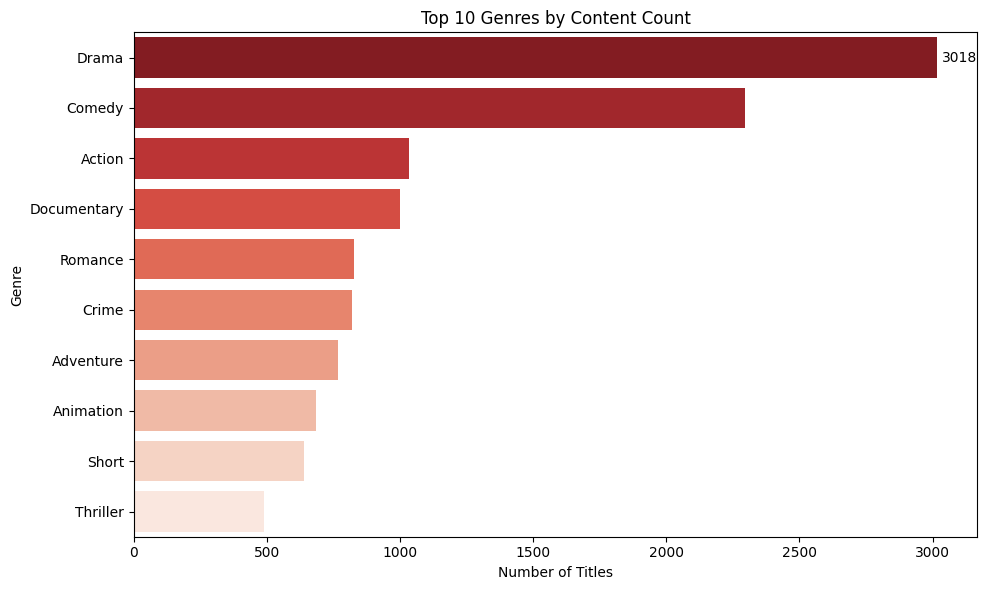

In [58]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=genre_count.values,
    y=genre_count.index,
    hue=genre_count.index,
    palette="Reds_r",
    legend=False
)
ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 Genres by Content Count")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

Drama: เป็น Genre ที่มีจำนวนคอนเทนต์มากที่สุด รองลงมาคือ Comedy

2. ประเทศไหนเป็นแหล่งผลิตคอนเทนต์หลัก

In [59]:
country_df = show_country.merge(country, on="country_id")

In [60]:
country_count = (
    country_df[country_df["country_name"] != "Unknown"]
    .groupby("country_name")["show_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

country_count

,show_id
country_name,
United States,3662
India,1046
United Kingdom,802
Canada,442
France,392
Japan,313
Spain,232
South Korea,226
Germany,226


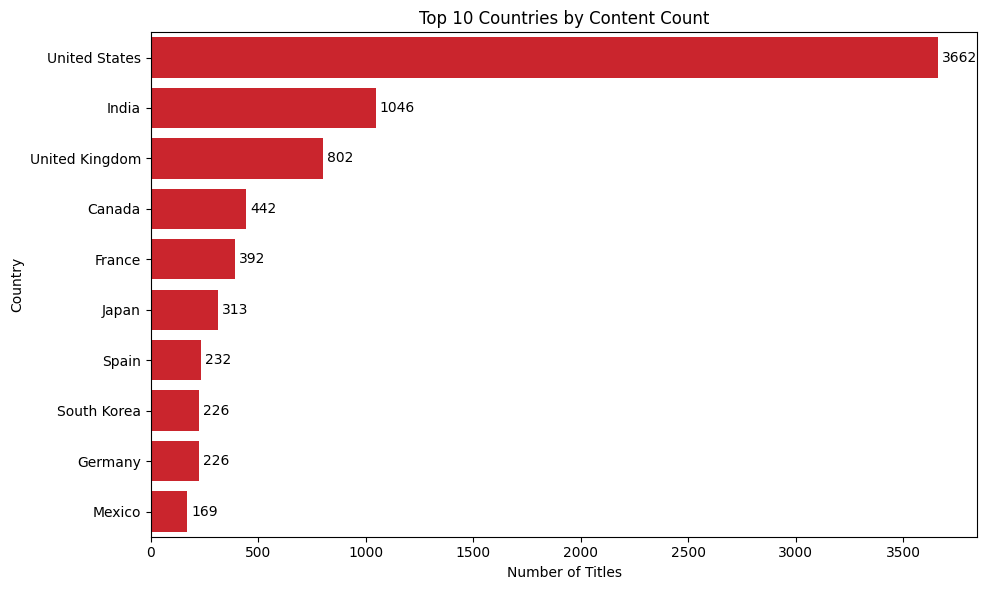

In [61]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=country_count.values,
    y=country_count.index,
    color="#E50914"
)

ax.bar_label(ax.containers[0], padding=3)

plt.title("Top 10 Countries by Content Count")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

สหรัฐอเมริกามีจำนวนคอนเทนต์บน Netflix มากที่สุดถึง 3,662 เรื่อง รองลงมาคืออินเดีย 1,046 เรื่อง และสหราชอาณาจักร 802 เรื่อง โดยสหรัฐอเมริกามีจำนวนคอนเทนต์มากกว่าอินเดียประมาณ 3.5 เท่า สะท้อนให้เห็นถึงสัดส่วนที่สูงของคอนเทนต์จากสหรัฐอเมริกาในชุดข้อมูลนี้

3. คะแนน TMDB เฉลี่ยของคอนเทนต์ที่เพิ่มในแต่ละปีเปลี่ยนแปลงอย่างไร

In [62]:
yearly_score = (
    df.groupby("year")["tmdb_score"]
    .mean()
    .sort_index()
)

yearly_score

,tmdb_score
year,
2008,6.138000
2009,4.904000
2010,5.500000
2011,6.362692
2012,6.515667
2013,6.184111
2014,6.756739
2015,6.546244
2016,6.267021


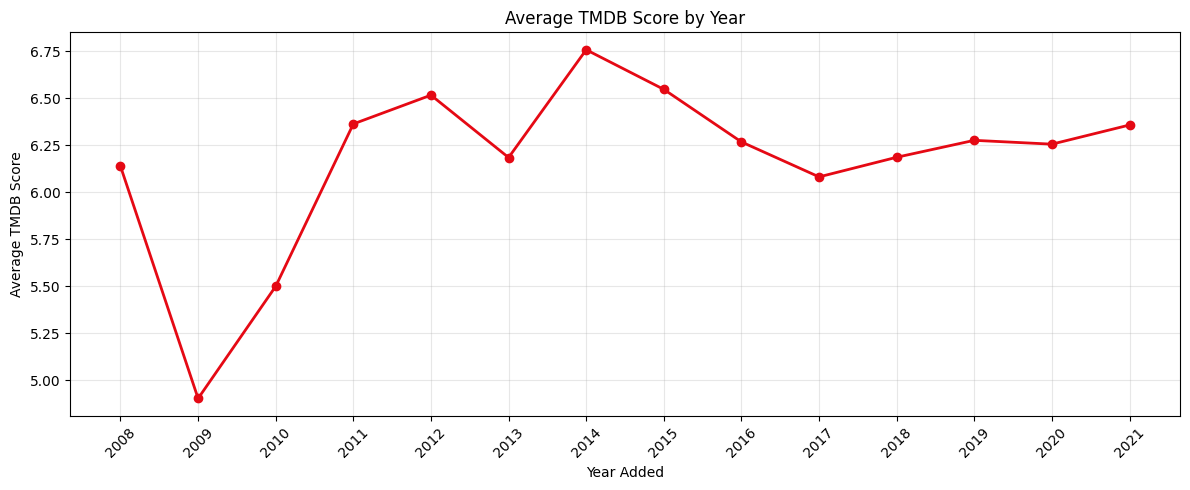

In [63]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_score.index,
    yearly_score.values,
    color="#E50914",
    marker="o",
    linewidth=2
)

plt.title("Average TMDB Score by Year")
plt.xlabel("Year Added")
plt.ylabel("Average TMDB Score")
plt.xticks(yearly_score.index, rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

จากกราฟพบว่า คะแนนเฉลี่ยของคอนเทนต์ในช่วงปี 2008–2014 มีการขึ้นลงค่อนข้างมาก โดยปี 2009 มีคะแนนต่ำที่สุด และปี 2014 มีคะแนนสูงที่สุด หลังจากปี 2017 คะแนนเฉลี่ยค่อนข้างคงที่อยู่ที่ประมาณ 6.1–6.4 คะแนน

4. ผู้กำกับหรือนักแสดงคนไหนมีผลงานมากที่สุด และมีคะแนนเฉลี่ยเท่าไร

In [64]:
director_df = bts[
    (bts["role"] == "director") &
    (bts["person_name"] != "Unknown")
]

director_df = director_df.merge(
    content[["show_id", "tmdb_score"]],
    on="show_id"
)

director_df = director_df.drop_duplicates(
    subset=["person_id", "show_id"]
)

In [65]:
director_stats = (
    director_df.groupby("person_name")
    .agg(
        content_count=("show_id", "nunique"),
        avg_score=("tmdb_score", "mean")
    )
    .sort_values("content_count", ascending=False)
    .head(10)
)

director_stats

,content_count,avg_score
person_name,,
Rajiv Chilaka,22,6.645636
Jan Suter,21,5.476190
Ra√∫l Campos,19,5.400000
Suhas Kadav,16,7.489250
Marcus Raboy,16,6.415125
Jay Karas,15,6.636467
Cathy Garcia-Molina,13,7.106923
Martin Scorsese,12,7.468333
Youssef Chahine,12,6.646250


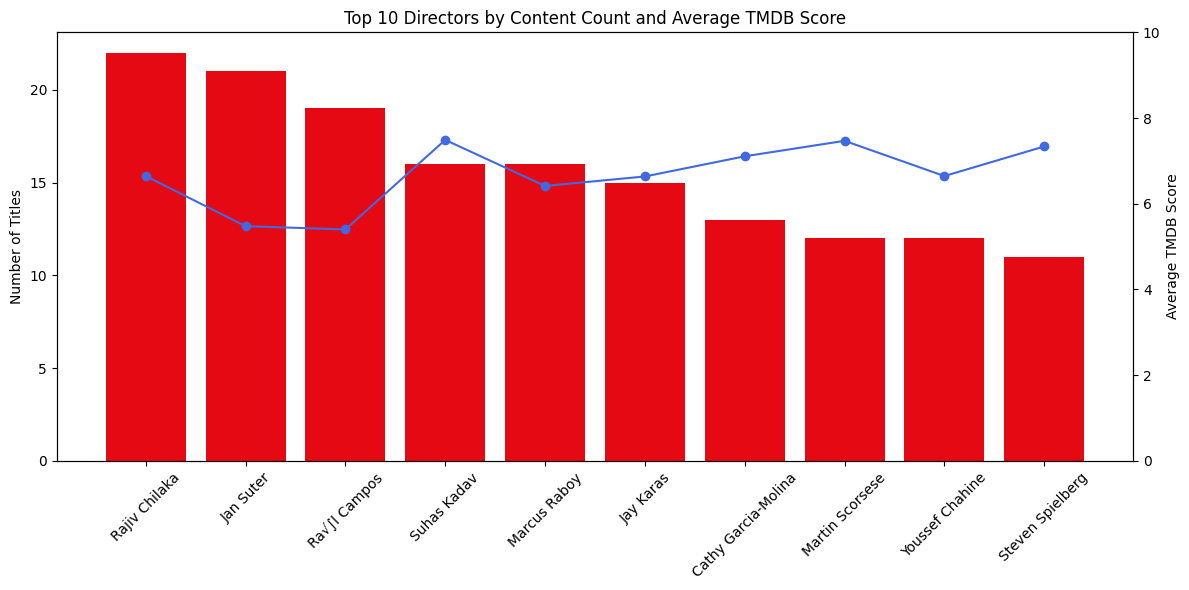

In [66]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    director_stats.index,
    director_stats["content_count"],
    color="#E50914"
)

ax1.set_ylabel("Number of Titles")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    director_stats.index,
    director_stats["avg_score"],
    color="royalblue",
    marker="o"
)

ax2.set_ylabel("Average TMDB Score")
ax2.set_ylim(0, 10)

plt.title("Top 10 Directors by Content Count and Average TMDB Score")
plt.tight_layout()
plt.show()

จากกราฟพบว่า Rajiv Chilaka เป็นผู้กำกับที่มีผลงานบน Netflix มากที่สุดจำนวน 22 เรื่อง รองลงมาคือ Jan Suter จำนวน 21 เรื่อง อย่างไรก็ตาม ผู้กำกับที่มีผลงานมากที่สุดไม่ได้มีคะแนนเฉลี่ยสูงที่สุด โดย Suhas Kadav และ Martin Scorsese มีคะแนนเฉลี่ยสูงประมาณ 7.5 คะแนน

แสดงให้เห็นว่าจำนวนผลงานที่มากไม่ได้หมายความว่าจะมีคะแนนเฉลี่ยสูงเสมอไป

5.1 Runtime มีความสัมพันธ์กับคะแนน TMDB หรือไม่



In [67]:
movie_df = df[df["type"] == "Movie"].copy()

In [68]:
movie_df["runtime"] = pd.to_numeric(
    movie_df["runtime_minutes"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

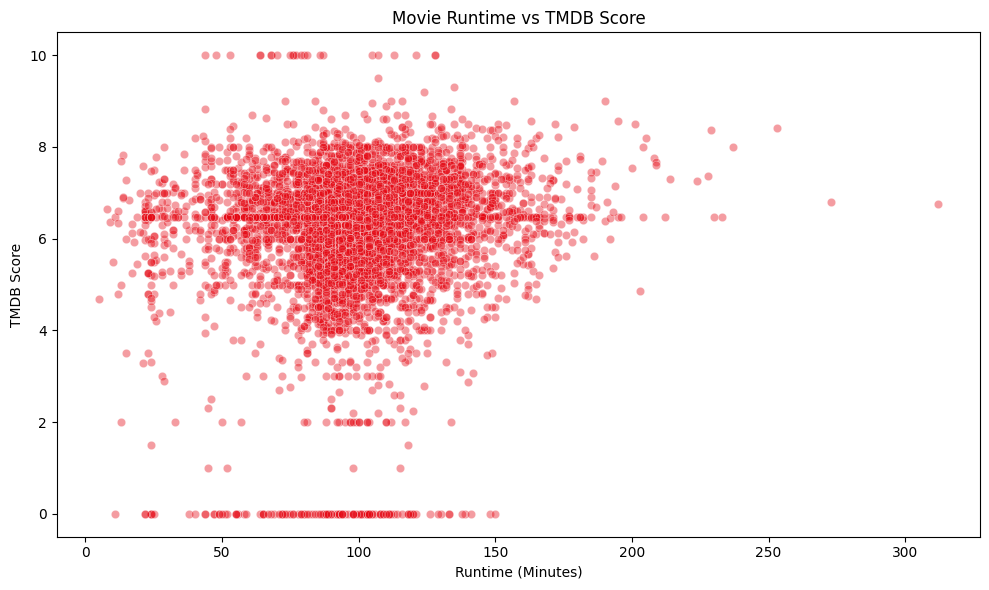

In [69]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=movie_df,
    x="runtime",
    y="tmdb_score",
    color="#E50914",
    alpha=0.4
)

plt.title("Movie Runtime vs TMDB Score")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("TMDB Score")
plt.tight_layout()
plt.show()

In [70]:
correlation = movie_df["runtime"].corr(movie_df["tmdb_score"])

print(f"Correlation: {correlation:.4f}")

Correlation: 0.1182


จากกราฟพบว่าภาพยนตร์ส่วนใหญ่มีความยาวประมาณ 60–150 นาที และมีคะแนน TMDB อยู่ในช่วง 5–8 คะแนน โดยมีค่า Correlation เท่ากับ 0.1182 ซึ่งแสดงถึงความสัมพันธ์เชิงบวกที่ต่ำมาก กล่าวคือ ภาพยนตร์ที่มีความยาวมากกว่าไม่ได้หมายความว่าจะได้รับคะแนนสูงกว่าเสมอไป

5.2 Genre vs TMDB Score

In [71]:
genre_score = genre_df.merge(
    content[["show_id", "tmdb_score"]],
    on="show_id"
)

genre_score = genre_score.drop_duplicates(
    subset=["show_id", "genres_id"]
)

In [72]:
top_genres = genre_count.index

genre_score = genre_score[
    genre_score["genres_name"].isin(top_genres)
]

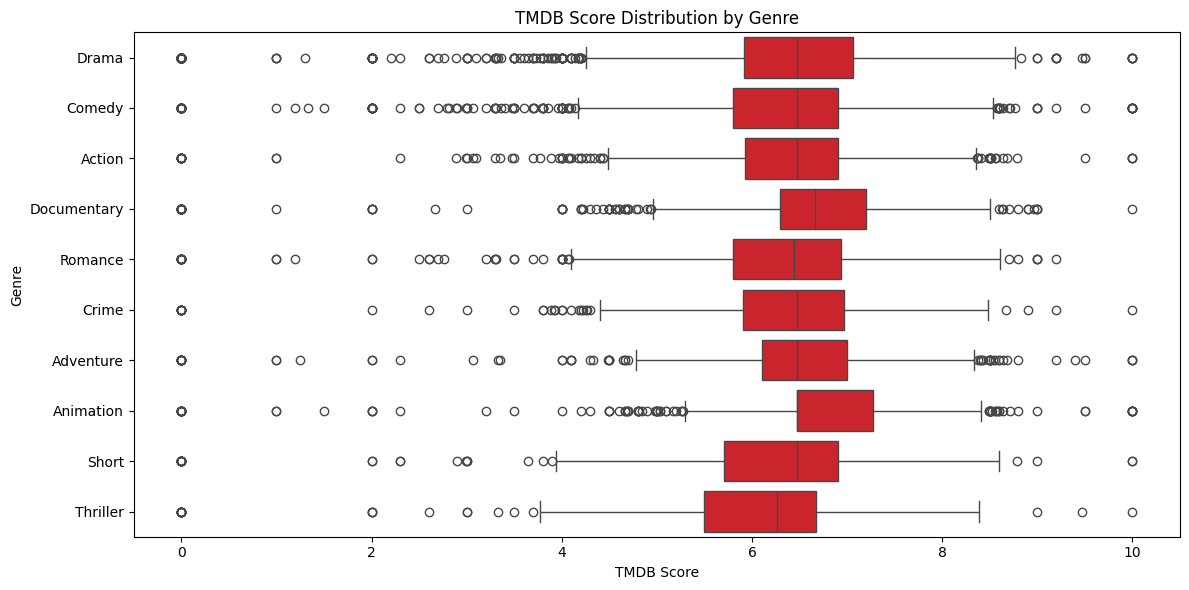

In [73]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=genre_score,
    x="tmdb_score",
    y="genres_name",
    order=top_genres,
    color="#E50914"
)

plt.title("TMDB Score Distribution by Genre")
plt.xlabel("TMDB Score")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [74]:
genre_score.groupby("genres_name")["tmdb_score"].mean().sort_values(
    ascending=False
)

,tmdb_score
genres_name,
Animation,6.527558
Documentary,6.505689
Adventure,6.427203
Action,6.339850
Crime,6.333559
Drama,6.288040
Comedy,6.230004
Romance,6.186763
Short,6.148390


จากกราฟพบว่า Animation มีคะแนน TMDB เฉลี่ยสูงที่สุดอยู่ที่ 6.53 คะแนน รองลงมาคือ Documentary ที่ 6.51 คะแนน ส่วน Thriller มีคะแนนเฉลี่ยต่ำที่สุดอยู่ที่ 5.97 คะแนน อย่างไรก็ตาม คะแนนของแต่ละ Genre มีการกระจายตัวใกล้เคียงกัน แสดงให้เห็นว่า Genre เพียงอย่างเดียวอาจไม่สามารถบอกได้ว่าคอนเทนต์จะได้รับคะแนนสูงหรือต่ำ

# Business Insights & Recommendations

1. ยกระดับคุณภาพคอนเทนต์
- Insight: คอนเทนต์มีคะแนน TMDB เฉลี่ย 6.25 และมีสัดส่วน High Quality Content เพียง 4.93%
- Recommendation: ให้ความสำคัญกับการคัดเลือกและพัฒนาคอนเทนต์ที่มีคุณภาพมากขึ้น
2. พิจารณาผู้กำกับจากทั้งจำนวนและคุณภาพผลงาน
- Insight: Rajiv Chilaka มีผลงานมากที่สุด 22 เรื่อง แต่ Suhas Kadav และ Martin Scorsese มีคะแนนเฉลี่ยสูงกว่า
- Recommendation: พิจารณาทั้งจำนวนผลงานและคะแนนเฉลี่ยในการเลือกผู้กำกับ
3. กระจายแหล่งผลิตคอนเทนต์
- Insight: สหรัฐอเมริกามีจำนวนคอนเทนต์มากที่สุด รองลงมาคืออินเดียและสหราชอาณาจักร
- Recommendation: พิจารณาเพิ่มความหลากหลายของคอนเทนต์จากประเทศอื่น ๆ
4. เพิ่มความหลากหลายของ Genre
- Insight: Drama และ Comedy มีจำนวนคอนเทนต์มากที่สุด แต่ Animation และ Documentary มีคะแนนเฉลี่ยสูงที่สุดในกลุ่ม 10 Genre ที่วิเคราะห์
- Recommendation: พิจารณาเพิ่มความหลากหลายของคอนเทนต์ โดยให้ความสำคัญกับทั้งจำนวนและคะแนนเฉลี่ย
5. ไม่ยึดติดกับความยาวของภาพยนตร์
- Insight: ความยาวของภาพยนตร์มีความสัมพันธ์กับคะแนน TMDB ค่อนข้างต่ำ โดยมี Correlation เท่ากับ 0.1182
- Recommendation: ให้ความสำคัญกับคุณภาพและความเหมาะสมของเนื้อหามากกว่าการกำหนดความยาวของภาพยนตร์


